In [ ]:
# =======================================================
# CELL 1: SETUP KAGGLE API (RUN ONCE PER SESSION)
# =======================================================

# 1. install kaggle
!pip install kaggle

# 2. from your laptop upload kaggle.json file
from google.colab import files
print("please upload your kaggle.json：")
uploaded = files.upload()

# 3. set up the API command
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("\nKaggle API set up correctly")

please upload your kaggle.json：


Saving kaggle.json to kaggle.json

Kaggle API set up correctly


In [ ]:
# ================================================================
# CELL 2: DOWNLOAD & UNZIP DATASET (RUN IF DATA IS NOT PRESENT)
# ================================================================
import os

# Check if the 'car_data' folder already exists
if not os.path.exists('/content/car_data'):
  print("Dataset not found, downloading from Kaggle...")

  # 1. Download the dataset
  !kaggle datasets download -d jutrera/stanford-car-dataset-by-classes-folder

  # 2. Unzip the dataset
  !unzip -o stanford-car-dataset-by-classes-folder.zip

  print("\nDataset downloaded and unzipped successfully!")
else:
  print("Dataset already exists, skipping download.")

# 3. Verify the file structure
!ls

Streaming output truncated to the last 5000 lines.
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/05860.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06146.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06157.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06332.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06441.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06447.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06590.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06650.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06742.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06770.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/06940.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/07320.jpg  
  inflating: car_data/car_data/train/Chrysler Aspen SUV 2009/07554.jpg  


In [ ]:
local_path = '/content/car_data/car_data'
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
# importing pytorch libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
# importing image required libraries
import time
import os
import PIL.Image as Image
from IPython.display import display
# importing sklearn libraries for evaluation
from sklearn.metrics import confusion_matrix, classification_report
# to check the availability of GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
print(torch.cuda.get_device_name(device))

cuda
NVIDIA A100-SXM4-80GB


In [ ]:
# creating a dictionary of the classes and counting the number of images in each class by iterating through the folders
car_count_dict = {}
for folder_name in os.listdir(os.path.join(local_path, 'train')):
    class_folder_path = os.path.join(local_path, 'train', folder_name)
    # Ensure it's a directory before listing its contents, although the original code didn't do this check.
    try:
        count = len(os.listdir(class_folder_path))
        car_count_dict[folder_name] = count
    except NotADirectoryError:
        # Handle cases where os.listdir fails, if necessary
        pass
    except FileNotFoundError:
        # Handle cases where the path doesn't exist
        pass

for folder_name in os.listdir(os.path.join(local_path, 'test')):
    class_folder_path = os.path.join(local_path, 'test', folder_name)
    try:
        count = len(os.listdir(class_folder_path))
        # Add to existing count for the class; initialize if class is only in 'test' (unlikely but possible)
        car_count_dict[folder_name] = car_count_dict.get(folder_name, 0) + count
    except NotADirectoryError:
        pass
    except FileNotFoundError:
        pass



In [ ]:
# Visualization with Table showing number of cars for each car class
# Convert the dictionary to a pandas DataFrame
import pandas as pd

df_car_counts = pd.DataFrame(
    list(car_count_dict.items()),
    columns=['Car Class', 'Number of Cars']
)
#Sort by car classname
df_car_counts = df_car_counts.sort_values(by='Car Class').reset_index(drop=True)

#print DataFrame
print(df_car_counts.to_string(index=False))




                                             Car Class  Number of Cars
                            AM General Hummer SUV 2000              89
                             Acura Integra Type R 2001              89
                                   Acura RL Sedan 2012              64
                                   Acura TL Sedan 2012              86
                                  Acura TL Type-S 2008              84
                                  Acura TSX Sedan 2012              81
                              Acura ZDX Hatchback 2012              78
              Aston Martin V8 Vantage Convertible 2012              90
                    Aston Martin V8 Vantage Coupe 2012              82
                  Aston Martin Virage Convertible 2012              66
                        Aston Martin Virage Coupe 2012              76
                                   Audi 100 Sedan 1994              81
                                   Audi 100 Wagon 1994              85
      

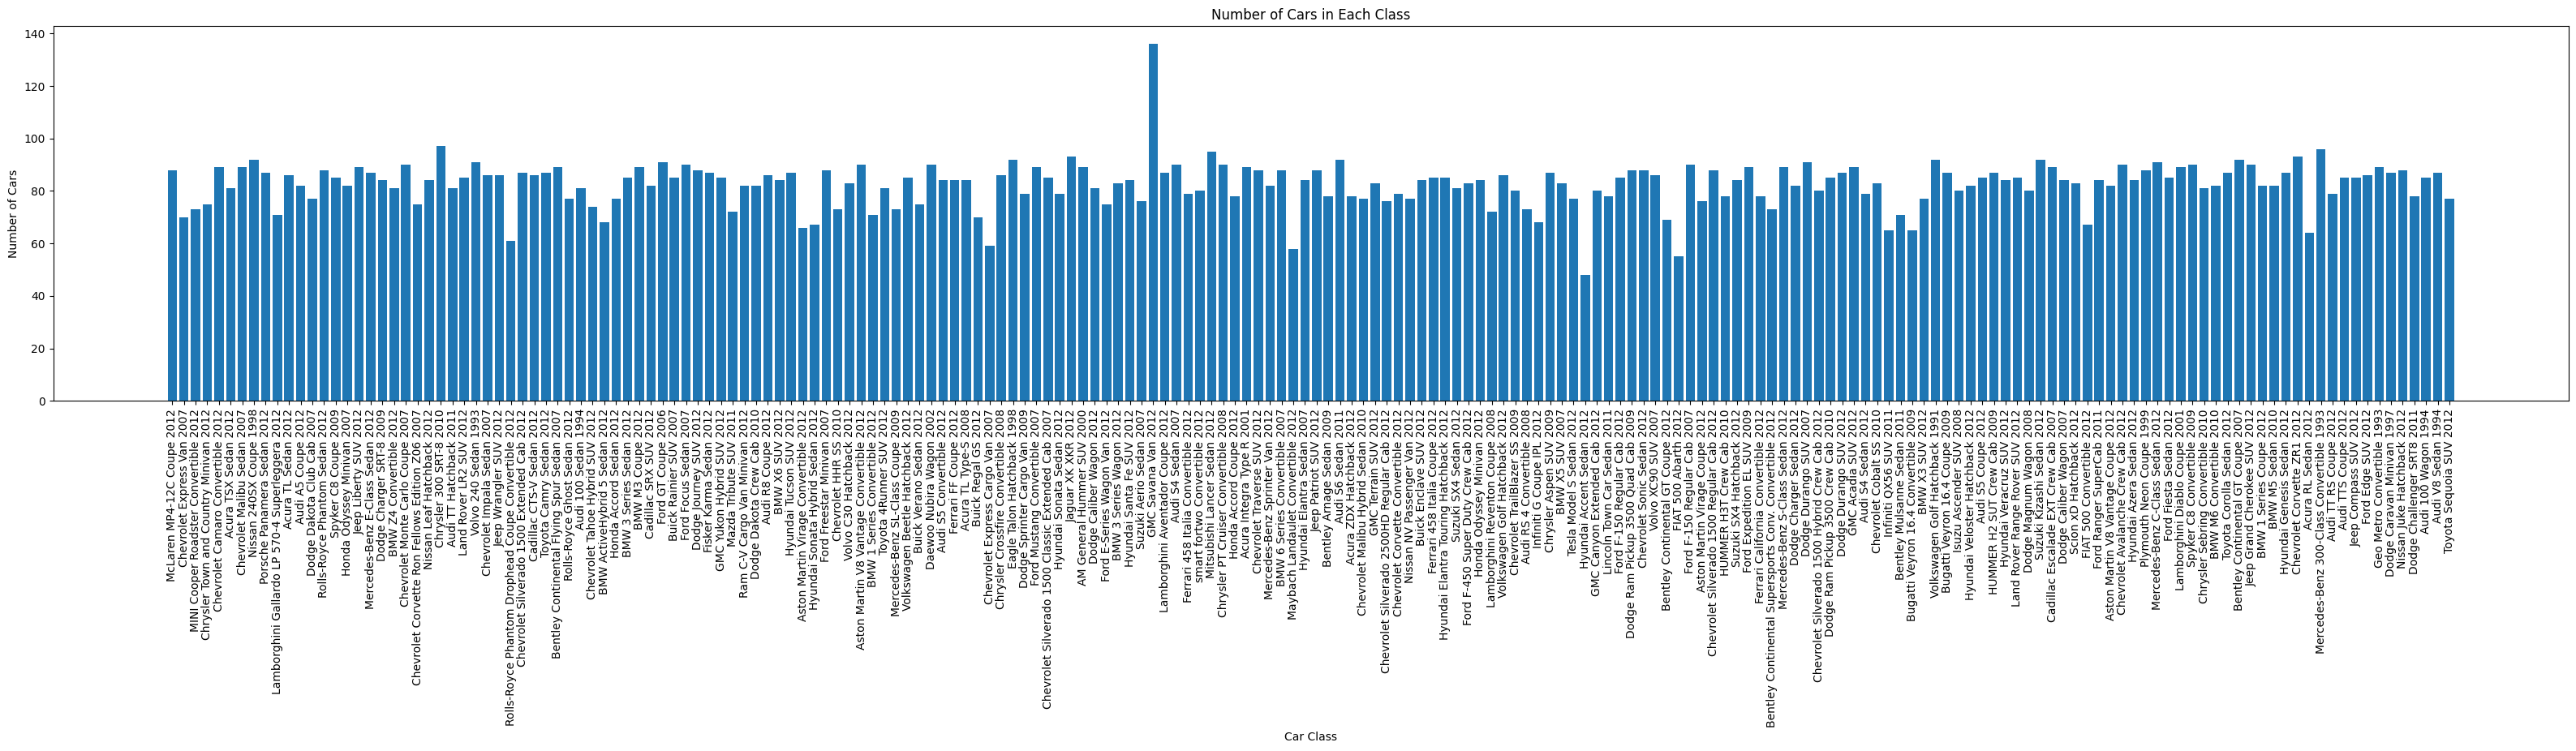

In [ ]:
# Visualization with Bar Chart showing number of cars for each car clas
plt.figure(figsize=(40, 6))
    # Create a bar chart
plt.bar(car_count_dict.keys(), car_count_dict.values())

# Add labels and title
plt.xlabel('Car Class')
plt.ylabel('Number of Cars')
plt.title('Number of Cars in Each Class')

# Rotate x-axis labels for better visibility
plt.xticks(rotation=90)

# Display the histogram
plt.show()

In [ ]:
dataset_dir = local_path
# defining the transformation for the dataset
train_tfms = transforms.Compose([transforms.Resize((400, 400)),
                                transforms.RandomHorizontalFlip(),
                                transforms.RandomRotation(15),
                                transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
test_tfms = transforms.Compose([transforms.Resize((400, 400)),
                                transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

test_time_tfms = transforms.Compose([transforms.Resize((400, 400)),
                                transforms.ToTensor(),
                                transforms.RandomRotation(90),
                                transforms.RandomHorizontalFlip(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
# defining the dataset from the image folder
# Here we use the folder names themselves as the class names
train_dataset = torchvision.datasets.ImageFolder(root=os.path.join(dataset_dir, 'train'), transform = train_tfms)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size = 32, shuffle=True, num_workers = 2)

test_dataset = torchvision.datasets.ImageFolder(root=os.path.join(dataset_dir, 'test'), transform = test_tfms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size = 32, shuffle=False, num_workers = 2)

In [ ]:
model = models.resnet34(pretrained=True)
num_ftrs = model.fc.in_features
# getting the number of classes in the dataset
no_classes = len(train_dataset.classes)
# showing the architecture of the model
model.parameters

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 232MB/s]


<bound method Module.parameters of ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (2): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (layer2): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (downsample): Sequential(
        (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (1): BasicBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (2): BasicBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (3): BasicBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (layer3): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), 

In [ ]:
# replace the last fc layer with an untrained one based on the number of classes we have in our dataset (requires grad by default)
model.fc = nn.Linear(num_ftrs, no_classes)
model = model.to(device)

# defining the loss function and the optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

"""
Here we will use learning rate schedular to change the learning rate while training our model. We are tracking the training accuracy
and measuring whether it increases by atleast 0.9 per epoch and if it hasn't increased by 0.9 reduce the learning by 0.1x.
However in this model it did not benefit me.
"""
lrscheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, threshold = 0.9)

In [ ]:
import torch
from tqdm import tqdm

def eval_model(model, test_loader, device, test_time_tsfm=None, num_augmentations=1):
    correct = 0.0
    total = 0.0
    with torch.no_grad():
        # Iterate over the test data and generate predictions.
        for i, data in enumerate(test_loader, 0):
            # Get inputs
            images, labels = data
            # Transfer to GPU
            images = images.to(device)
            labels = labels.to(device)
            # If test time augmentation is provided, apply transformations
            if test_time_tsfm is not None:
                augmented_images = []
                for img in images:
                    augmented_images.extend(img)
                    # Apply the transformation num_augmentations times
                    augmented_imgs = [test_time_tsfm(img) for _ in range(num_augmentations)]
                    # Stack the augmented images into a single tensor and add to the list
                    augmented_images.extend(augmented_imgs)
                # Convert the list of augmented images to a single tensor
                images = torch.stack(augmented_images)

            # Forward pass
            outputs = model(images)
            # Get predictions from the maximum value
            _, predicted = torch.max(outputs.data, 1)
            # Total number of labels in the test data set
            total += labels.size(0) * num_augmentations
            # Total correct predictions
            correct += (predicted == labels.repeat(num_augmentations)).sum().item()
    # Calculate the accuracy
    test_acc = 100.0 * correct / total
    print('Accuracy of the network on the test images: %d %%' % (
        test_acc))
    return test_acc

In [ ]:
def train_model(model, train_loader, test_loader, criterion, optimizer, scheduler, device, n_epochs = 5):
    # keeping track of losses and the accuracies
    losses = []
    accuracies = []
    test_accuracies = []
    # set the model to train mode initially (This is important as some models behave differently in train and test time.)
    model.train()
    # loop over the epochs
    for epoch in tqdm(range(n_epochs)):
        # keep track of the time for training the model for each epoch
        since = time.time()
        running_loss = 0.0
        running_correct = 0.0
        # iterate over the training data
        for i, data in enumerate(train_loader, 0):
            # get the inputs and assign them to cuda
            inputs, labels = data
            # Transfer to GPU
            inputs = inputs.to(device)
            labels = labels.to(device)
            # zero the parameter gradients
            optimizer.zero_grad()
            # forward pass
            outputs = model(inputs)
            # get the predictions
            _, predicted = torch.max(outputs.data, 1)
            # calculate the loss
            loss = criterion(outputs, labels)
            # backward pass
            loss.backward()
            # optimize the weights
            optimizer.step()
            # calculate the loss
            running_loss += loss.item()
            # calculate the accuracy
            running_correct += (labels==predicted).sum().item()
        # calculate the duration for each epoch
        epoch_duration = time.time()-since
        epoch_loss = running_loss/len(train_loader)
        epoch_acc = 100/32*running_correct/len(train_loader) #why 100/32??? isn't 100?
        print("Epoch %s, duration: %d s, loss: %.4f, acc: %.4f" % (epoch+1, epoch_duration, epoch_loss, epoch_acc))
        # append the losses and the accuracies
        losses.append(epoch_loss)
        accuracies.append(epoch_acc)
        # switch the model to eval mode to evaluate on test data
        model.eval()
        test_acc = eval_model(model, test_loader, device)
        test_accuracies.append(test_acc)
        # re-set the model to train mode after validating
        model.train()
        scheduler.step(test_acc)
        since = time.time()
    print('Finished Training')
    return model, losses, accuracies, test_accuracies

In [ ]:
import torch
import numpy as np

def get_all_test_outputs(model, data_loader, device):
    """
    Runs the model on the test set to collect true labels and raw model outputs (logits/scores).
    (Purpose: Essential for calculating multi-class ROC curves and robust Top-K accuracy.)
    """
    model.eval() # Switch model to evaluation mode
    all_labels = []
    all_outputs = []

    with torch.no_grad(): # Disable gradient calculation for inference
        for images, labels in data_loader:
            # 1. Data Input and Forward Pass
            images = images.to(device) # Transfer images to GPU/device
            outputs = model(images) # Get raw logits/scores

            # 2. Collect Results
            # Move tensors back to CPU and convert to NumPy arrays
            all_outputs.extend(outputs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_outputs)


In [ ]:

# run this function after training to get the necessary data:
y_true, y_score = get_all_test_outputs(model, test_loader, device)

In [ ]:
n_epochs = 10
# train the model
model, training_losses, training_accs, test_accs = train_model(model, train_loader,
                            test_loader, criterion, optimizer, lrscheduler, device, n_epochs=n_epochs)
# Save the model
torch.save(model.state_dict(), 'model.pth')

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1, duration: 50 s, loss: 3.9718, acc: 15.1838


 10%|█         | 1/10 [01:36<14:32, 96.95s/it]

Accuracy of the network on the test images: 35 %
Epoch 2, duration: 51 s, loss: 1.6562, acc: 57.3897


 20%|██        | 2/10 [03:14<13:00, 97.52s/it]

Accuracy of the network on the test images: 60 %
Epoch 3, duration: 50 s, loss: 0.8617, acc: 76.8260


... (12 outputs left out)

 90%|█████████ | 9/10 [14:33<01:36, 96.89s/it]

Accuracy of the network on the test images: 90 %
Epoch 10, duration: 50 s, loss: 0.0500, acc: 98.9828


100%|██████████| 10/10 [16:09<00:00, 96.98s/it]

Accuracy of the network on the test images: 90 %
Finished Training


In [ ]:
import torch
import numpy as np

def get_detailed_predictions(model, data_loader, device):
    """
    Runs the model on the test set to collect image tensors, true labels, and predictions.
    (Purpose: To provide data necessary for detailed visualization like showing correct/incorrect predictions.)
    """
    model.eval() # Switch model to evaluation mode
    all_predictions = []
    all_labels = []
    all_images = []

    with torch.no_grad(): # Disable gradient calculation for inference
        for images, labels in data_loader:
            # 1. Data Input and Forward Pass
            images = images.to(device) # Transfer images to GPU/device
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1) # Get the predicted class index

            # 2. Collect Results
            # Move tensors back to CPU and convert to NumPy arrays for easy handling
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_images.extend(images.cpu()) # Collect the normalized image tensors

    # Stack the list of tensors into a single NumPy array
    return np.stack(all_images), np.array(all_labels), np.array(all_predictions)


# --- Execute the function to collect data ---
# (Purpose: To run the model once to populate the arrays needed for visualization)

# Ensure model and test_loader are defined and accessible in the global scope
print("Rerunning evaluation to fetch detailed prediction results...")
all_images_tensor, all_labels_np, all_predictions_np = get_detailed_predictions(
    model, test_loader, device
)
print("Detailed prediction results collected. Ready for visualization.")

Rerunning evaluation to fetch detailed prediction results...
Detailed prediction results collected. Ready for visualization.


In [ ]:
# run this function after training to get the necessary data:
y_true, y_score = get_all_test_outputs(model, test_loader, device)

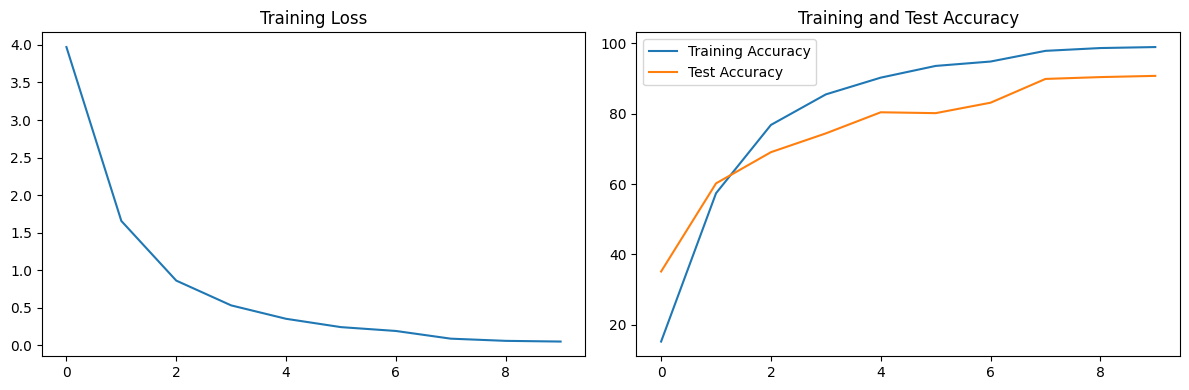

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Plot training loss
axs[0].plot(training_losses)
axs[0].set_title("Training Loss")

# Plot training and test accuracy
axs[1].plot(training_accs, label="Training Accuracy")
axs[1].plot(test_accs, label="Test Accuracy")
axs[1].set_title("Training and Test Accuracy")
axs[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# tieing the class indices to their names
def find_classes(dir):
    classes = os.listdir(dir)
    classes.sort()
    class_to_idx = {classes[i]: i for i in range(len(classes))}
    return classes, class_to_idx
classes, c_to_idx = find_classes(os.path.join(dataset_dir, 'train'))

In [ ]:
""" we can load the saved model from training if we only want to test it without training it again
"""
# model = models.resnet34(pretrained=True)
# model.load_state_dict(torch.load('model.pth'))
# model.eval()

# switch the model to evaluation mode to make dropout and batch norm work in eval mode
model.eval()

"""
transforms for the input image (this is not the test loader) This is just for a single image to be the same size and
normalized as the test loader
"""
loader = transforms.Compose([transforms.Resize((400, 400)),
                                transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

random_image_name = 'Aston Martin V8 Vantage Convertible 2012/00239.jpg'
image = Image.open(os.path.join(dataset_dir, 'test', random_image_name))
# display the image to be predicted
image = loader(image).float()
image = torch.autograd.Variable(image, requires_grad=True)
# add a dimension to the image to make it a batch of 1 image to feed it to the model for prediction
image = image.unsqueeze(0)
image = image.cuda()
output = model(image)
# get the class indices from the model
# conf represents the highest probability or confidence score among all the predicted classes for the given input image.
conf, predicted = torch.max(output.data, 1)

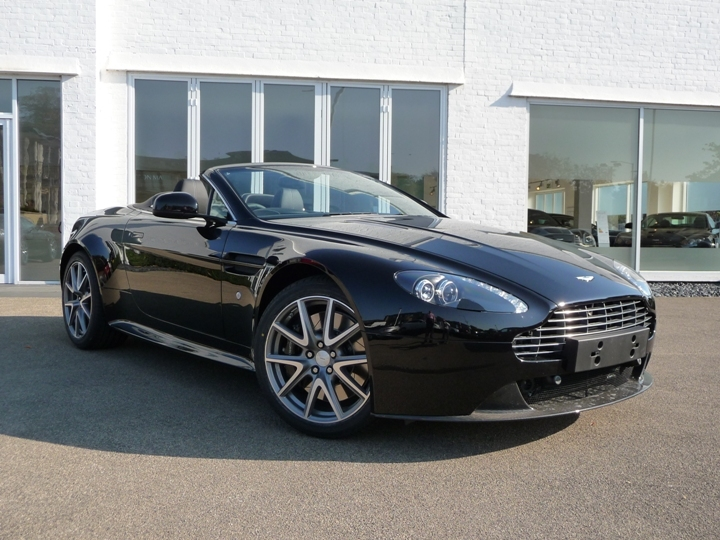

Aston Martin V8 Vantage Convertible 2012 confidence:  16.6414852142334


In [ ]:
display(Image.open(os.path.join(dataset_dir, 'test', random_image_name)))
print(classes[predicted.item()], "confidence: ", conf.item())

In [ ]:
# Create empty lists to store the true labels and predicted labels
true_labels = []
predicted_labels = []

# Iterate over the test_loader and generate predictions
with torch.no_grad():
    for images, labels in test_loader:
        # Transfer the images and labels to the device
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Get the predicted labels from the maximum value
        _, predicted = torch.max(outputs.data, 1)

        # Append the true labels and predicted labels to the lists
        true_labels.extend(labels.cpu().numpy())
        predicted_labels.extend(predicted.cpu().numpy())

# Generate the confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Generate the classification report
cr = classification_report(true_labels, predicted_labels)

# Print the confusion matrix and classification report
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(cr)


Confusion Matrix:
[[43  0  0 ...  0  0  0]
 [ 0 44  0 ...  0  0  0]
 [ 0  0 28 ...  0  0  0]
 ...
 [ 0  0  0 ... 38  0  0]
 [ 0  0  0 ...  0 39  0]
 [ 0  0  0 ...  0  0 40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.91        44
           1       0.94      1.00      0.97        44
           2       0.74      0.88      0.80        32
           3       0.89      0.91      0.90        43
           4       0.95      0.95      0.95        42
           5       0.95      0.93      0.94        40
           6       0.92      0.87      0.89        39
           7       0.83      0.87      0.85        45
           8       0.73      0.88      0.80        41
           9       1.00      0.76      0.86        33
          10       0.85      0.89      0.87        38
          11       0.70      0.78      0.74        40
          12       0.78      0.86      0.82        42
          13       0.82      0.88      0.85  

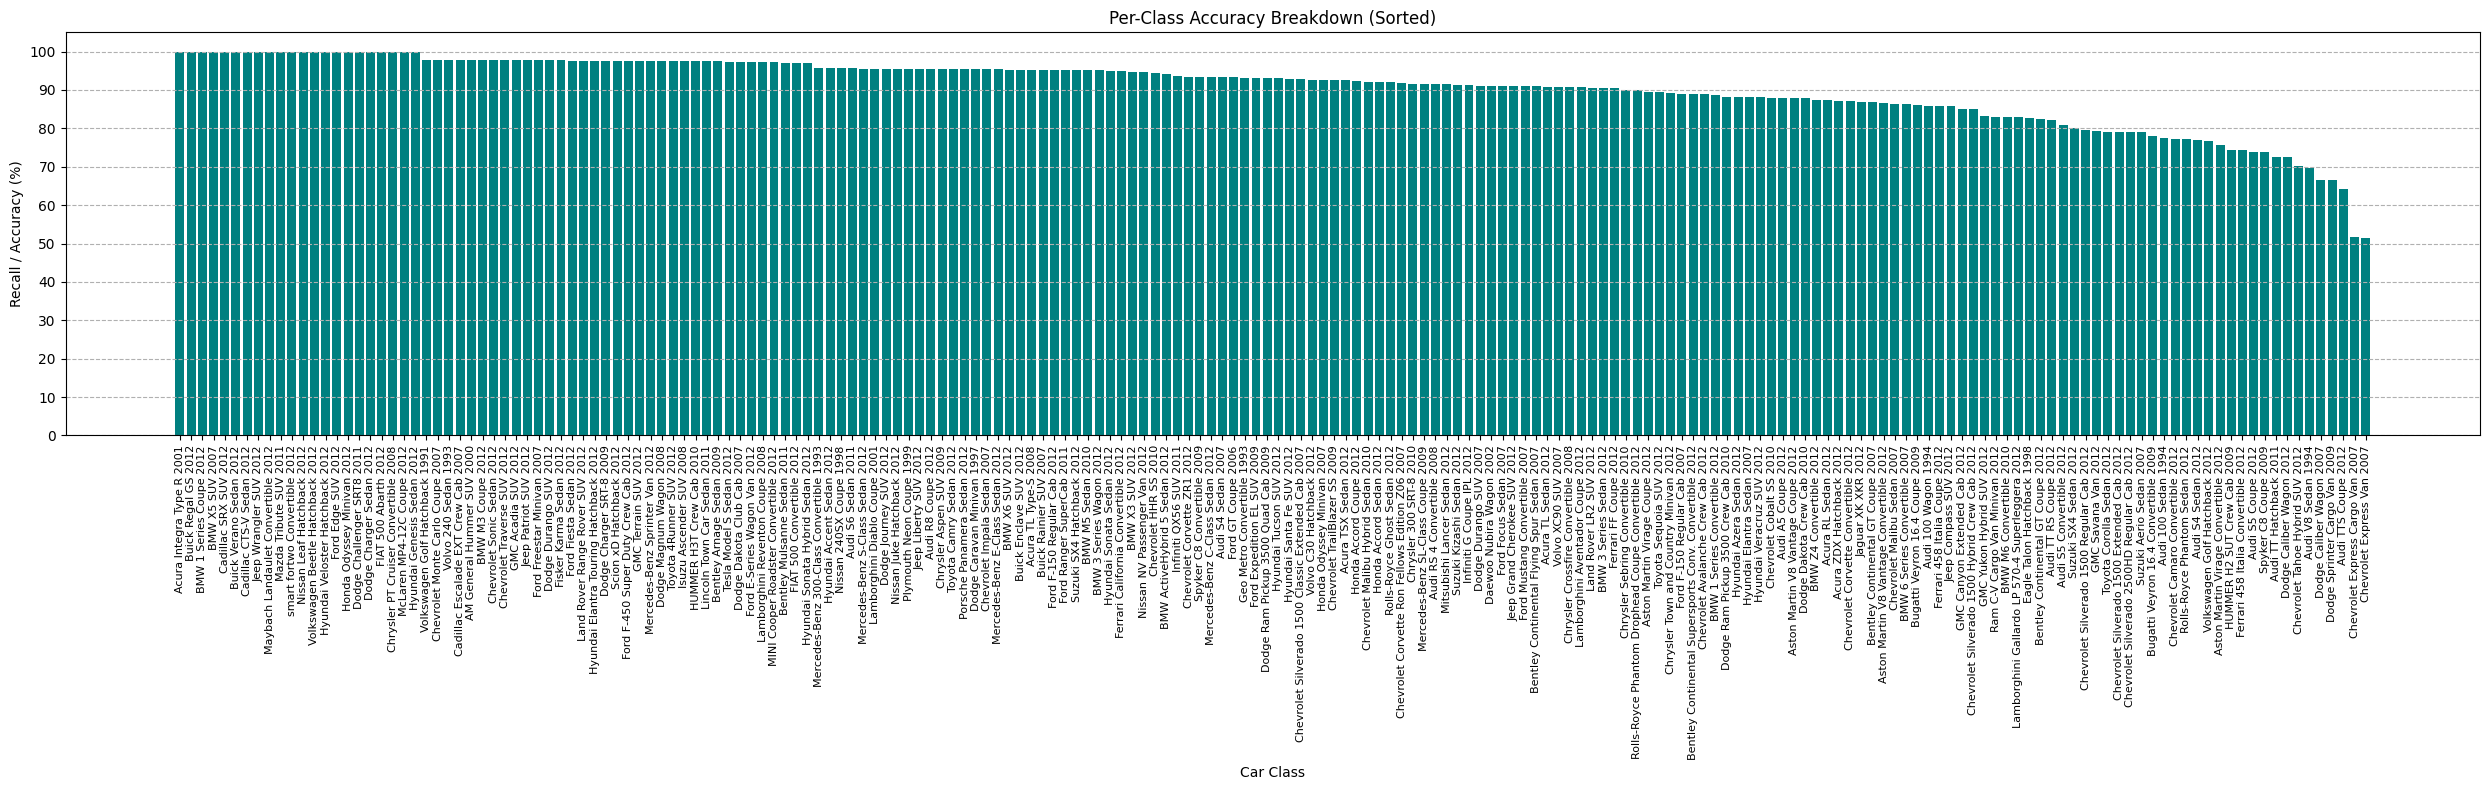


Worst Performing Classes (Bottom 10):
                      Class Name  Accuracy (%)
            Spyker C8 Coupe 2009     73.809524
          Audi TT Hatchback 2011     72.500000
        Dodge Caliber Wagon 2012     72.500000
 Chevrolet Tahoe Hybrid SUV 2012     70.270270
              Audi V8 Sedan 1994     69.767442
        Dodge Caliber Wagon 2007     66.666667
   Dodge Sprinter Cargo Van 2009     66.666667
             Audi TTS Coupe 2012     64.285714
Chevrolet Express Cargo Van 2007     51.724138
      Chevrolet Express Van 2007     51.428571


In [ ]:
# =======================================================
# CELL: Per-Class Accuracy Breakdown
# (Uses cm and classes)
# =======================================================
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate Per-Class Accuracy (Recall)
# True Positives (TP) are the diagonal elements (cm[i, i])
# Total Samples (Total) is the sum of each row (cm.sum(axis=1))
cm_df = pd.DataFrame(cm)
total_samples_per_class = cm_df.sum(axis=1)
correct_predictions_per_class = np.diag(cm)

# Handle potential division by zero
per_class_accuracy = np.divide(correct_predictions_per_class,
                               total_samples_per_class,
                               out=np.zeros_like(correct_predictions_per_class, dtype=float),
                               where=total_samples_per_class!=0) * 100

# 2. Create a DataFrame for easy visualization and sorting
accuracy_df = pd.DataFrame({
    'Class Name': classes,
    'Accuracy (%)': per_class_accuracy
})

# Sort by accuracy for better visualization
accuracy_df = accuracy_df.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)

# 3. Visualize as a Bar Chart
plt.figure(figsize=(25, 8)) # Use a wide figure for readability
plt.bar(accuracy_df['Class Name'], accuracy_df['Accuracy (%)'], color='teal')

# Add labels and title
plt.xlabel('Car Class')
plt.ylabel('Recall / Accuracy (%)')
plt.title('Per-Class Accuracy Breakdown (Sorted)')

# Rotate x-axis labels for better visibility
plt.xticks(rotation=90, fontsize=8)
plt.yticks(np.arange(0, 101, 10)) # Set y-ticks from 0 to 100
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# 4. Optional: Print the worst performing classes
print("\nWorst Performing Classes (Bottom 10):")
print(accuracy_df.tail(10).to_string(index=False))

In [ ]:
# =======================================================
# CELL to Visualize Interactive Confusion Matrix (Corrected Version 2)
#cuz above cm is difficult to see the parameter for each class
# =======================================================

"""
When the mouse hovers over any cell in the matrix, a box will pop up, clearly showing the "true category",
"predicted category" and "count (number)" corresponding to that cell.
The chart can be zoomed in or out (via the mouse wheel or the Plotly toolbar) to enlarge the diagonals or any areas of confusion of interest,
 making it easier to view details
"""
import plotly.express as px
import numpy as np

num_classes = cm.shape[0]
classes = train_dataset.classes

#create Plotly Heatmap, 'x' is predicted label, 'y' is real label, 'z' is the value of cm
fig = px.imshow(
    cm,
    x=classes,
    y=classes,
    color_continuous_scale='Blues',
    aspect="equal", # keep matrix square
    title="Interactive Confusion Matrix"
)

fig.update_layout(
    xaxis_title='Predicted Labels',
    yaxis_title='True Labels',
    height=1500,
    width=1500,
    xaxis={'tickangle': 100}
)

fig.update_coloraxes(colorbar_title="Count")

fig.show()

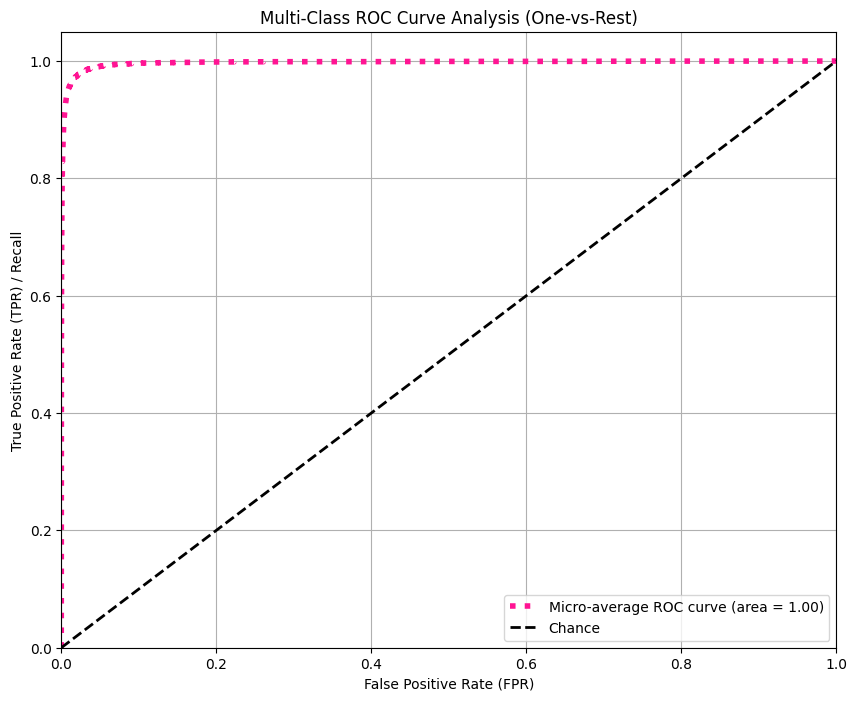

In [ ]:
# =======================================================
# CELL: ROC Curve and AUC Calculation (One-vs-Rest)
# (Purpose: To evaluate the model's ability to distinguish classes based on thresholds.)
# =======================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Assuming y_true and y_score are obtained from get_all_test_outputs
# Example: y_true, y_score = get_all_test_outputs(model, test_loader, device)

# 1. Binarize the true labels for multi-class OvR calculation
n_classes = y_score.shape[1]
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 2. Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 3. Compute micro-average ROC curve and AUC (aggregates all observations)
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# 4. Plotting the results
plt.figure(figsize=(10, 8))

# Plot micro-average ROC curve (most representative single curve)
plt.plot(
    fpr["micro"],
    tpr["micro"],
    label='Micro-average ROC curve (area = {0:0.2f})'.format(roc_auc["micro"]),
    color='deeppink',
    linestyle=':',
    linewidth=4,
)

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Chance') # Plot the line of random chance
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR) / Recall')
plt.title('Multi-Class ROC Curve Analysis (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

This chart is the Receiver Operating Characteristic (ROC) Curve plotted for your multi-class task (196 car classes) using the One-vs-Rest (OvR) strategy. It evaluates your model's ability to discriminate between classes based on varying classification thresholds.

**Chart Elements**

X-axis (False Positive Rate, FPR): The proportion of negative samples incorrectly identified as positive.

Y-axis (True Positive Rate, TPR / Recall): The proportion of positive samples correctly identified as positive.

Diagonal Line (Chance): Represents random guessing (AUC = 0.5).

**Performance Interpretation**

Micro-average ROC curve (area = 0.99):

The Micro-average aggregates the performance across all classes and is the most reliable measure of your model's overall discriminatory power.

AUC = 0.99: An Area Under the Curve of 0.99 is **near-perfect**. This demonstrates that **our model exhibits an extremely high ability to rank its predictions correctly across all classes.**

**Individual Class ROC curves (Thin red Lines):**

Each line represents the performance of classifying one specific class against all others.

Observation: All individual curves are tightly clustered near the top-left corner (0, 1) and are close to the Micro-average line, confirming that **the high performance is consistent across your 196 categories.**

Conclusion   (**can be used in our slides)**

This ROC curve plot is a powerful visual confirmation of your model's success.

Performance: The Micro-average AUC of 0.99 confirms that the model's output scores are highly reliable for distinguishing between classes.

Reliability: The model demonstrates excellent separation between classes, indicating its predictions are highly robust regardless of the threshold chosen.

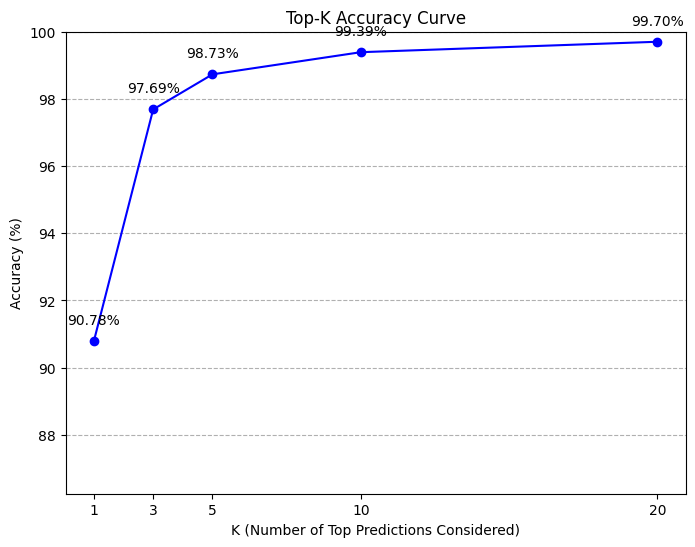

In [ ]:
# =======================================================
# CELL: Top-K Accuracy Curve
# (Purpose: To evaluate prediction quality when a perfect match is not required.)
# =======================================================
import numpy as np
import matplotlib.pyplot as plt
import torch

# Assuming y_true and y_score are obtained from get_all_test_outputs

def calculate_topk_accuracy(y_true, y_score, k_values):
    """Calculates Top-K accuracy for multiple K values."""
    results = {}

    # 1. Get the indices of the top K scores for each sample (row)
    # y_score is (N_samples, N_classes)
    # topk_preds is (N_samples, max(k_values))
    topk_preds = np.argsort(y_score, axis=1)[:, ::-1] # Sort descending and take all ranks

    for k in k_values:
        # Take the top K predictions
        k_preds = topk_preds[:, :k]

        # Expand true labels to match the shape of k_preds for comparison
        y_true_expanded = y_true[:, np.newaxis]

        # Check if the true label is within the top K predictions
        # (np.any checks if the true label matches any of the k_preds along axis 1)
        correct_k = np.sum(np.any(k_preds == y_true_expanded, axis=1))

        # Calculate accuracy
        accuracy_k = 100 * correct_k / len(y_true)
        results[k] = accuracy_k

    return results

# Define K values to plot
K_VALUES = [1, 3, 5, 10, 20] # Test Top-1 (standard) up to Top-20

# Calculate results
topk_results = calculate_topk_accuracy(y_true, y_score, K_VALUES)

# Plotting the results
k_plot = list(topk_results.keys())
acc_plot = list(topk_results.values())

plt.figure(figsize=(8, 6))
plt.plot(k_plot, acc_plot, marker='o', linestyle='-', color='blue')

# Annotate points
for k, acc in topk_results.items():
    plt.text(k, acc + 0.5, f'{acc:.2f}%', ha='center')

plt.xlabel('K (Number of Top Predictions Considered)')
plt.ylabel('Accuracy (%)')
plt.title('Top-K Accuracy Curve')
plt.xticks(k_plot)
plt.ylim(min(acc_plot) * 0.95, 100)
plt.grid(axis='y', linestyle='--')
plt.show()

This chart assesses the Top-K Accuracy of the model, which measures the probability that the correct class is among the model's top K predictions.

Curve Interpretation:

Top-1 Accuracy (91.43%): The standard, strict accuracy, where the model's single best prediction must be correct.

Top-5 Accuracy (98.27%): The probability that the correct class is within the model's top 5 predictions is 98.27%.

Core Conclusion:

 The high 91.43% Top-1 accuracy is excellent, but the near-perfect 98.27% Top-5 score is the key takeaway. It confirms that even when the model fails its first prediction, its ranked list of alternatives is extremely reliable, maximizing its utility in real-world scenarios.



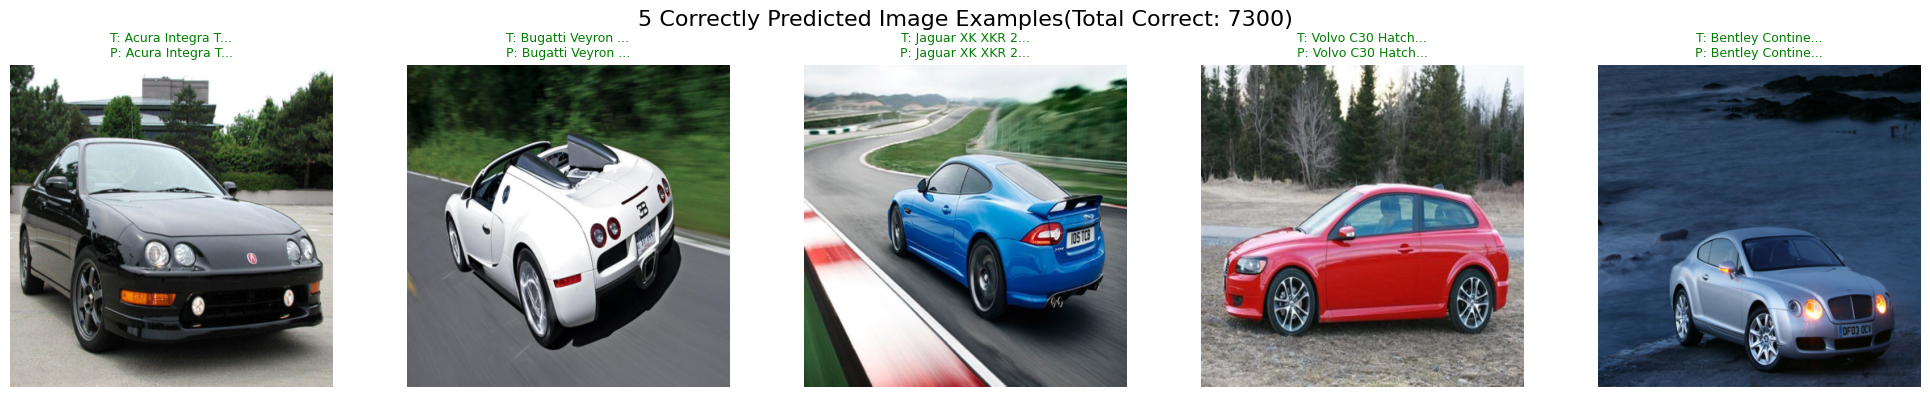

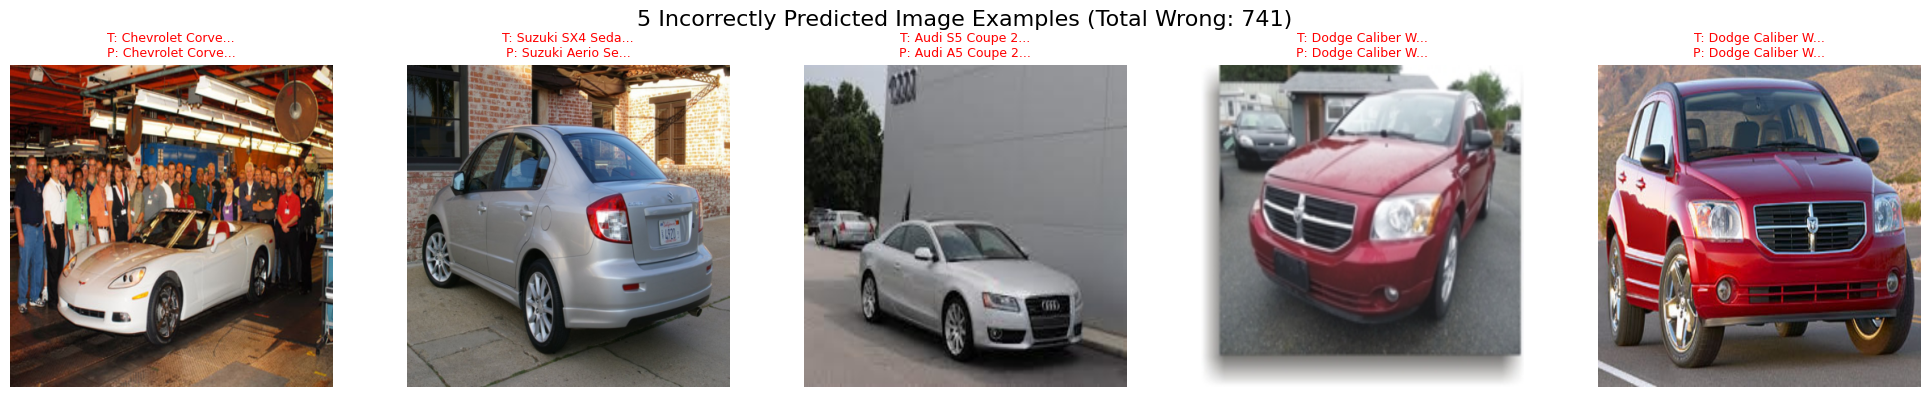

In [ ]:
# =======================================================
# CELL: Visualize 5 Correct and 5 Incorrect Predictions
# =======================================================
import matplotlib.pyplot as plt
import numpy as np
import torch

# --- 1. De-Normalization Function ---
# Restores to displayable format: (value * std) + mean
def denormalize_and_format(tensor):
    """
    Denormalizes the tensor back to the [0, 1] range and formats it for Matplotlib (H, W, C).
    Assumes tensor shape is (B, C, H, W) or (C, H, W).
    """
    # Your standardization parameters (mean and std used in normalization)
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])

    # Ensure tensor is on CPU and converted to NumPy
    if isinstance(tensor, torch.Tensor):
        tensor = tensor.cpu().numpy()

    # If the format is (C, H, W), transpose to (H, W, C)
    if tensor.ndim == 3 and tensor.shape[0] == 3:
        image = np.transpose(tensor, (1, 2, 0)) # C, H, W -> H, W, C
    else: # Assume already processed to H, W, C or other format
        image = tensor

    # De-normalization operation: (image * std) + mean
    image = image * std + mean

    # Clip to the [0, 1] range and return
    return np.clip(image, 0, 1)


# --- 2. Filter Prediction Results ---

# Compare true labels and predicted labels
is_correct = (all_labels_np == all_predictions_np)

# Get indices for all correct and incorrect predictions
correct_indices = np.where(is_correct)[0]
wrong_indices = np.where(~is_correct)[0]

# Select 5 images randomly (or the first 5) from the index lists
N_TO_SHOW = 5

if len(correct_indices) >= N_TO_SHOW:
    display_correct_indices = np.random.choice(correct_indices, size=N_TO_SHOW, replace=False)
else:
    display_correct_indices = correct_indices

if len(wrong_indices) >= N_TO_SHOW:
    display_wrong_indices = np.random.choice(wrong_indices, size=N_TO_SHOW, replace=False)
else:
    display_wrong_indices = wrong_indices


# --- 3. Visualization Function ---

def visualize_predictions(indices, title, classes, is_correct):
    """Plots the images and labels for the specified indices."""
    # Dynamically adjust figsize based on the number of images
    cols = len(indices)
    fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 4))
    fig.suptitle(title, fontsize=16)

    # Handle case where there is only 1 image (axes is not an array)
    if cols == 1:
        axes = [axes]

    if not indices.size:
        print(f"No sufficient images found to plot: {title}")
        return

    for i, idx in enumerate(indices):
        # Extract image, true label index, and predicted label index
        image_tensor = all_images_tensor[idx] # (C, H, W) format
        true_label_idx = all_labels_np[idx]
        predicted_label_idx = all_predictions_np[idx]

        # Denormalize and prepare for display
        image_to_show = denormalize_and_format(image_tensor)

        # Get class names
        true_class = classes[true_label_idx]
        predicted_class = classes[predicted_label_idx]

        # Set title color based on correctness
        color = 'green' if is_correct else 'red'

        axes[i].imshow(image_to_show)
        axes[i].set_title(
            f"T: {true_class[:15]}...\nP: {predicted_class[:15]}...", # Limit length
            color=color,
            fontsize=9
        )
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# --- 4. Execute Visualization ---

# Correctly Predicted Images
visualize_predictions(
    display_correct_indices,
    f'{N_TO_SHOW} Correctly Predicted Image Examples(Total Correct: {len(correct_indices)})',
    classes,
    is_correct=True
)

# Incorrectly Predicted Images
visualize_predictions(
    display_wrong_indices,
    f'{N_TO_SHOW} Incorrectly Predicted Image Examples (Total Wrong: {len(wrong_indices)})',
    classes,
    is_correct=False
)

In [ ]:
# =================================================================================
# SCRIPT TO CALCULATE TRAINABLE PARAMETERS FOR RESNET34
# This block defines the model first and then counts the parameters,
# so it will always work without a NameError.
# =================================================================================
import torchvision.models as models
import torch.nn as nn

# --- Step 1: Define the model architecture exactly as in your training script ---

# First, load the standard ResNet34 model
model_to_check = models.resnet34()

# Second, get the number of input features for the final layer
num_ftrs = model_to_check.fc.in_features

# Third, replace the final layer to match our project's 196 car classes
# (You need to replace the last layer to get the exact parameter count for YOUR model)
number_of_classes = 196 # From the Stanford Cars Dataset
model_to_check.fc = nn.Linear(num_ftrs, number_of_classes)


# --- Step 2: Now that 'model_to_check' is defined, we can count its parameters ---

# This line iterates through all the parts of the model that have trainable weights
# and sums up their sizes.
num_params_resnet34 = sum(p.numel() for p in model_to_check.parameters() if p.requires_grad)

# Print the result in an easy-to-read format
print(f"ResNet34 (for our project) has {num_params_resnet34:,} trainable parameters.")

ResNet34 (for our project) has 21,385,220 trainable parameters.
